# Tema 5 · Teoría de valores extremos y riesgos catastróficos (POT / GPD) — Ejercicio práctico (Python)
**Luiz Luzuriaga** · Máster en Ciencias Actuariales y Financieras · Matemática Actuarial de la Estabilidad y Solvencia

Contenido: (A) Casos 1 y 2 y la tabla de Excel (VaR/TVaR por POT-GPD), (B) la muestra Burr de la práctica de R y la elección del umbral,
(C) ajuste MLE e incertidumbre (Wald, perfil, bootstrap) y métodos alternativos, (D) diagnósticos gráficos, (E) de la severidad al SCR anual,
(F) capa XL 40 xs 20, (G) datos con límites de póliza (censura) y no estacionariedad.
**Datos compartidos:** `t5_siniestros.csv` son los 2.000 siniestros de `actuar::rburr(2000, 2, 1.5, 5)` con `set.seed(123)` en R (ver el script `.R`); se usan en Excel, Python y R.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize, special

T_AÑOS, N_TOT = 40, 2000
claims = pd.read_csv("t5_siniestros.csv")["perdida_MEUR"].to_numpy()

def var_gpd(p, u, xi, sig, n, Nu):
    r = (n/Nu)*(1 - p)
    return u + sig*np.expm1(-xi*np.log(r))/xi if abs(xi) > 1e-8 else u - sig*np.log(r)
def tvar_gpd(p, u, xi, sig, n, Nu):
    v = var_gpd(p, u, xi, sig, n, Nu); return (v + sig - xi*u)/(1 - xi)
def nivel_retorno(m, u, xi, sig, lam_u):
    x = lam_u*m; return u + sig*np.expm1(xi*np.log(x))/xi if abs(xi) > 1e-8 else u + sig*np.log(x)

## (A) Casos 1 y 2 y la tabla del taller de Excel
$VaR_p=u+\frac\sigma\xi\big[r^{-\xi}-1\big]$, $r=\frac n{N_u}(1-p)$; $TVaR_p=\frac{VaR_p+\sigma-\xi u}{1-\xi}$ ($\xi<1$); $\lambda_u=N_u/T$; nivel de retorno $x_m=u+\frac\sigma\xi[(\lambda_um)^\xi-1]$.
Para $\xi\to0$ se usa `expm1` (estabilidad numérica) y la rama $u-\sigma\ln r$.

In [2]:
caso = {"Caso 1 · Terremoto": dict(n=2000, T=40, u=10, Nu=80, xi=.35, sig=6), "Caso 2 · Inundación": dict(n=1500, T=30, u=5, Nu=60, xi=.25, sig=4)}
filas = []
for k, c in caso.items():
    lam = c["Nu"]/c["T"]; v = var_gpd(.995, c["u"], c["xi"], c["sig"], c["n"], c["Nu"]); t = tvar_gpd(.995, c["u"], c["xi"], c["sig"], c["n"], c["Nu"])
    filas.append([k, c["n"]/c["Nu"], lam, v, t, t - v, t/v - 1, nivel_retorno(100, c["u"], c["xi"], c["sig"], lam), nivel_retorno(200, c["u"], c["xi"], c["sig"], lam)])
cas = pd.DataFrame(filas, columns=["caso", "n/Nu", "λ_u", "VaR 99,5 %", "TVaR 99,5 %", "brecha", "TVaR/VaR−1", "retorno 100 a", "retorno 200 a"]).set_index("caso")
c1 = caso["Caso 1 · Terremoto"]
tabla_excel = pd.DataFrame([[p, var_gpd(p, c1["u"], c1["xi"], c1["sig"], 2000, 80), tvar_gpd(p, c1["u"], c1["xi"], c1["sig"], 2000, 80)] for p in (.97, .99, .995, .999)], columns=["p", "VaR", "TVaR"]).set_index("p")
tabla_excel["TVaR/VaR"] = tabla_excel.TVaR/tabla_excel.VaR; tabla_excel["TVaR−VaR"] = tabla_excel.TVaR - tabla_excel.VaR
print(f"Periodo de retorno del VaR 99,5 % de severidad (Caso 1): {1/(2000/40*.005):.1f} años | evento de 50 M€: {1/(80/40*(1 + .35*(50 - 10)/6)**(-1/.35)):.1f} años")
print("Casos 1 y 2:"); print(cas.round(3).to_string()); print("\nTabla del taller (Caso 1):"); tabla_excel.round(2)

Periodo de retorno del VaR 99,5 % de severidad (Caso 1): 4.0 años | evento de 50 M€: 15.6 años
Casos 1 y 2:
                     n/Nu  λ_u  VaR 99,5 %  TVaR 99,5 %  brecha  TVaR/VaR−1  retorno 100 a  retorno 200 a
caso                                                                                                     
Caso 1 · Terremoto   25.0  2.0      28.352       47.465  19.113       0.674        102.365        132.431
Caso 2 · Inundación  25.0  2.0      15.909       24.878   8.970       0.564         49.170         60.554

Tabla del taller (Caso 1):


,VaR,TVaR,TVaR/VaR,TVaR−VaR
p,,,,
0.970,11.82,22.02,1.86,10.21
0.990,20.71,35.70,1.72,15.00
0.995,28.35,47.46,1.67,19.11
0.999,55.20,88.77,1.61,33.57


**Lectura.** El VaR 99,5 % de severidad (28,35 M€) se supera de media **cada 4 años** (λ=2 eventos/año): no es un suceso 1-en-200; el 1-en-200 es 132,4 M€ (4,7 veces mayor). El cociente $TVaR/VaR$ **decrece** con $p$ (1,86 → 1,61, límite $1/(1-\xi)=1{,}54$) pero la brecha absoluta **crece** (10,2 → 33,6 M€).
Los valores de la diapositiva de Excel se reproducen exactamente (11,82/22,02; 20,71/35,70; 28,35/47,46; 55,20/88,77).

## (B) La muestra Burr y la elección del umbral
Burr(α=2, γ=1,5, θ=5): $\xi=1/(\alpha\gamma)=1/3$ y $VaR_{99,5\%}$ verdadero = 27,85 M€. Se calculan los estadísticos descriptivos, la función de exceso medio y el ajuste por umbral.

In [3]:
alpha_b, gam_b, th_b = 2.0, 1.5, 5.0
def burr_sf(x): return (1/(1 + (x/th_b)**gam_b))**alpha_b
def burr_ppf(p): return th_b*((1 - p)**(-1/alpha_b) - 1)**(1/gam_b)
var_verd = burr_ppf(.995)
from scipy import integrate
tv_verd = var_verd + integrate.quad(burr_sf, var_verd, np.inf, limit=500)[0]/burr_sf(var_verd)      # E[X|X>v] = v + ∫_v^∞ S(x)dx / S(v)
x = np.sort(claims)[::-1]
print(f"n = {len(x)}  mediana = {np.median(x):.2f}  p95 = {np.quantile(x, .95):.2f}  máximo = {x[0]:.2f}  siguiente = {x[1]:.2f}")
print(f"Verdad: ξ = {1/(alpha_b*gam_b):.4f}   VaR 99,5 % = {var_verd:.2f}   TVaR 99,5 % = {tv_verd:.2f}")

def mle_gpd(exc):
    f = lambda p: np.inf if p[1] <= 0 else -np.sum(stats.genpareto.logpdf(exc, p[0], 0, p[1]))
    ini = [0.2, exc.mean()]; r = optimize.minimize(f, ini, method="Nelder-Mead", options=dict(xatol=1e-9, fatol=1e-10, maxiter=4000))
    return r.x, -r.fun
def hessiana(f, x0, h=(1e-4, 1e-3)):
    H = np.zeros((2, 2)); x0 = np.array(x0, float)
    for i in range(2):
        for j in range(2):
            ei = np.eye(2)[i]*h[i]; ej = np.eye(2)[j]*h[j]
            H[i, j] = (f(x0 + ei + ej) - f(x0 + ei - ej) - f(x0 - ei + ej) + f(x0 - ei - ej))/(4*h[i]*h[j])
    return H
def ajuste(u):
    exc = claims[claims > u] - u; Nu = len(exc); (xi, sg), ll = mle_gpd(exc)
    nll = lambda p: -np.sum(stats.genpareto.logpdf(exc, p[0], 0, p[1])); cov = np.linalg.inv(hessiana(nll, [xi, sg]))
    return dict(u=u, Nu=Nu, lam=Nu/T_AÑOS, xi=xi, sig=sg, se_xi=np.sqrt(cov[0, 0]), se_sig=np.sqrt(cov[1, 1]), cov=cov, ll=ll, exc=exc)
us = [5, 7.5, 10, 12.5, 15, 20]; fits = {u: ajuste(u) for u in us}
sens = []
for u in us:
    f = fits[u]; sens.append([u, f["Nu"], f["lam"], f["xi"], f["xi"] - 1.96*f["se_xi"], f["xi"] + 1.96*f["se_xi"], f["sig"], f["sig"] - f["xi"]*u,
                              var_gpd(.995, u, f["xi"], f["sig"], N_TOT, f["Nu"]), tvar_gpd(.995, u, f["xi"], f["sig"], N_TOT, f["Nu"])])
sens = pd.DataFrame(sens, columns=["u", "Nu", "λ_u", "ξ", "ξ inf (95 %)", "ξ sup (95 %)", "σ", "σ* = σ−ξu", "VaR 99,5 %", "TVaR 99,5 %"]).set_index("u")
sens.loc["verdad"] = [np.nan, np.nan, 1/3, np.nan, np.nan, np.nan, np.nan, var_verd, tv_verd]
sens.round(2)

n = 2000  mediana = 2.81  p95 = 11.70  máximo = 63.59  siguiente = 57.51
Verdad: ξ = 0.3333   VaR 99,5 % = 27.85   TVaR 99,5 % = 42.67


,Nu,λ_u,ξ,ξ inf (95 %),ξ sup (95 %),σ,σ* = σ−ξu,"VaR 99,5 %","TVaR 99,5 %"
u,,,,,,,,,
5.0,495.0,12.38,0.25,0.14,0.36,3.36,2.10,27.34,39.37
7.5,251.0,6.28,0.27,0.11,0.42,3.90,1.88,27.47,40.14
10.0,137.0,3.42,0.26,0.05,0.47,4.67,2.05,27.53,40.06
12.5,81.0,2.02,0.28,-0.01,0.56,5.32,1.84,27.58,40.74
15.0,54.0,1.35,0.39,-0.04,0.82,5.06,-0.76,27.06,42.98
20.0,23.0,0.57,0.06,-0.44,0.56,10.19,8.91,28.72,40.21
verdad,NaN,NaN,0.33,NaN,NaN,NaN,NaN,27.85,42.67


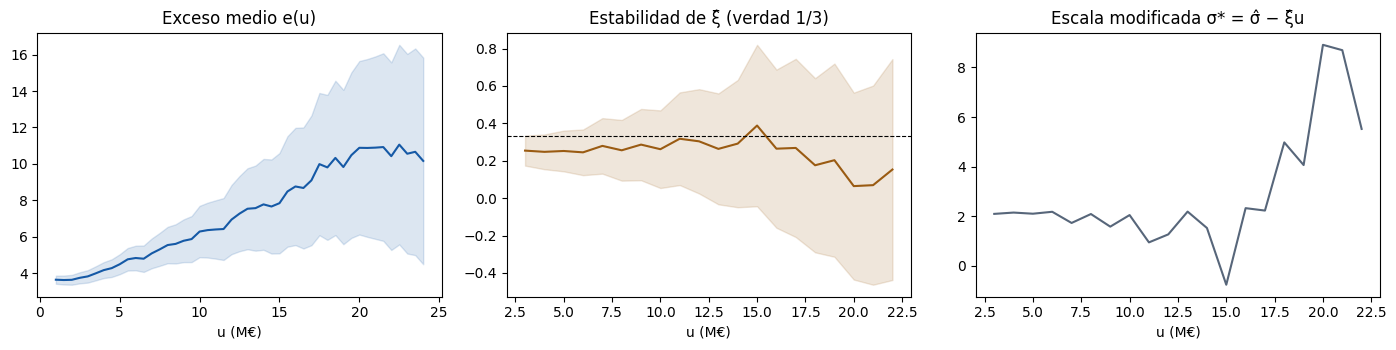

In [4]:
# Gráficos de diagnóstico del umbral: MRL y estabilidad de parámetros
ug = np.linspace(1, 24, 47); mrl, lo, hi, nn = [], [], [], []
for u in ug:
    e = claims[claims > u] - u; nn.append(len(e)); mrl.append(e.mean()); se = e.std(ddof=1)/np.sqrt(len(e)); lo.append(e.mean() - 1.96*se); hi.append(e.mean() + 1.96*se)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(ug, mrl, color="#1559a6"); ax[0].fill_between(ug, lo, hi, color="#1559a6", alpha=.15); ax[0].set_title("Exceso medio e(u)"); ax[0].set_xlabel("u (M€)")
ugs = np.arange(3, 22.1, 1.0); XI, SS, LO, HI = [], [], [], []
for u in ugs:
    f = ajuste(u); XI.append(f["xi"]); LO.append(f["xi"] - 1.96*f["se_xi"]); HI.append(f["xi"] + 1.96*f["se_xi"]); SS.append(f["sig"] - f["xi"]*u)
ax[1].plot(ugs, XI, color="#9a5b12"); ax[1].fill_between(ugs, LO, HI, color="#9a5b12", alpha=.15); ax[1].axhline(1/3, color="k", ls="--", lw=.8); ax[1].set_title("Estabilidad de ξ̂ (verdad 1/3)"); ax[1].set_xlabel("u (M€)")
ax[2].plot(ugs, SS, color="#57667a"); ax[2].set_title("Escala modificada σ* = σ̂ − ξ̂u"); ax[2].set_xlabel("u (M€)")
plt.tight_layout(); plt.show()

**Lectura.** Con esta muestra (la de `set.seed(123)` en R; no coincide con la de la diapositiva, que tiene 139 excedencias y un máximo de 88,6 M€) el exceso medio es aproximadamente lineal entre ≈ 5 y 15 M€; $\hat\xi$ es estable (0,25–0,28) entre $u=5$ y $12{,}5$ y se vuelve errático por encima de 15 (menos de 55 excesos, IC enormes). Se elige **u = 10 M€** ($N_u=137$, $\lambda_u=3{,}4$ eventos/año).
El VaR 99,5 % es muy robusto al umbral (27,1–28,7 M€; verdad 27,85) porque está cerca de los datos; el TVaR depende de $\hat\xi$ y varía más (39–43 M€; verdad ≈ 42,7). $\hat\xi\approx0{,}26$ queda por debajo del verdadero 1/3, pero dentro del intervalo.

## (C) Ajuste MLE en u = 10: incertidumbre y métodos alternativos
Intervalos: Wald (delta), verosimilitud perfil de $\xi$ y bootstrap paramétrico; contrastes con PWM, Hill y Pickands.

In [5]:
u = 10.0; f10 = fits[10]; exc = f10["exc"]; Nu = f10["Nu"]; xi_h, sg_h = f10["xi"], f10["sig"]
def var_de(xi, sg, Nu_=Nu): return var_gpd(.995, u, xi, sg, N_TOT, Nu_)
def tvar_de(xi, sg, Nu_=Nu): return tvar_gpd(.995, u, xi, sg, N_TOT, Nu_)
# Wald para VaR (método delta numérico)
g = lambda p: var_de(p[0], p[1]); d = np.array([(g([xi_h + 1e-5, sg_h]) - g([xi_h - 1e-5, sg_h]))/2e-5, (g([xi_h, sg_h + 1e-4]) - g([xi_h, sg_h - 1e-4]))/2e-4])
se_var = np.sqrt(d @ f10["cov"] @ d)
# perfil de ξ
xg = np.linspace(.05, .9, 200); prof = []
for xv in xg:
    r = optimize.minimize_scalar(lambda s: -np.sum(stats.genpareto.logpdf(exc, xv, 0, s)), bounds=(.1, 30), method="bounded"); prof.append(-r.fun)
prof = np.array(prof); ok = xg[prof >= f10["ll"] - stats.chi2.ppf(.95, 1)/2]
# bootstrap paramétrico (B = 1000)
rng = np.random.default_rng(2024); B = 1000; boot = np.empty((B, 3))
for b in range(B):
    yb = stats.genpareto.rvs(xi_h, 0, sg_h, Nu, random_state=rng); (xb, sb), _ = mle_gpd(yb); boot[b] = [xb, var_de(xb, sb), tvar_de(xb, sb)] if xb < .98 else [xb, np.nan, np.nan]
q = lambda a: np.nanquantile(a, [.025, .975])
res = pd.DataFrame({"estimación": [xi_h, var_de(xi_h, sg_h), tvar_de(xi_h, sg_h)],
                    "Wald": [f"[{xi_h - 1.96*f10['se_xi']:.2f}; {xi_h + 1.96*f10['se_xi']:.2f}]", f"[{var_de(xi_h, sg_h) - 1.96*se_var:.2f}; {var_de(xi_h, sg_h) + 1.96*se_var:.2f}]", "—"],
                    "Perfil": [f"[{ok.min():.2f}; {ok.max():.2f}]", "—", "—"],
                    "Bootstrap (B=1000)": [f"[{q(boot[:, 0])[0]:.2f}; {q(boot[:, 0])[1]:.2f}]", f"[{q(boot[:, 1])[0]:.2f}; {q(boot[:, 1])[1]:.2f}]", f"[{q(boot[:, 2])[0]:.2f}; {q(boot[:, 2])[1]:.2f}]"],
                    "verdadero": [1/3, var_verd, tv_verd]}, index=["ξ", "VaR 99,5 %", "TVaR 99,5 %"])
print(f"u = {u}: Nu = {Nu} (λ_u = {Nu/T_AÑOS:.2f}/año)  ξ̂ = {xi_h:.4f} (EE {f10['se_xi']:.4f})  σ̂ = {sg_h:.4f} (EE {f10['se_sig']:.4f})  logL = {f10['ll']:.3f}   EE VaR = {se_var:.2f}")
res.round(2)

u = 10.0: Nu = 137 (λ_u = 3.42/año)  ξ̂ = 0.2615 (EE 0.1059)  σ̂ = 4.6654 (EE 0.6262)  logL = -383.836   EE VaR = 2.23


,estimación,Wald,Perfil,Bootstrap (B=1000),verdadero
ξ,0.26,[0.05; 0.47],[0.09; 0.50],[0.01; 0.47],0.33
"VaR 99,5 %",27.53,[23.16; 31.90],—,[23.37; 32.11],27.85
"TVaR 99,5 %",40.06,—,—,[29.97; 56.16],42.67


In [6]:
# Métodos alternativos: PWM (Hosking–Wallis), Hill y Pickands
y = np.sort(exc); n_e = len(y); F = (np.arange(1, n_e + 1) - .35)/n_e; a0 = y.mean(); a1 = np.mean(y*(1 - F))
xi_pwm = 2 - a0/(a0 - 2*a1); sg_pwm = 2*a0*a1/(a0 - 2*a1)
k = Nu; xi_hill = np.mean(np.log(x[:k]/x[k])); kk = Nu//4
xi_pick = np.log((x[kk - 1] - x[2*kk - 1])/(x[2*kk - 1] - x[4*kk - 1]))/np.log(2) if 4*kk <= len(x) else np.nan
alt = pd.DataFrame({"ξ": [xi_h, xi_pwm, xi_hill, xi_pick, 1/3], "VaR 99,5 %": [var_de(xi_h, sg_h), var_de(xi_pwm, sg_pwm), u + (x[k]*0 + 0) if False else np.nan, np.nan, var_verd]},
                   index=["GPD-MLE (u=10)", "PWM / L-momentos", f"Hill (k={k})", f"Pickands (k={kk})", "verdad"])
# VaR con Hill (cola de Pareto): x_(k+1)·(k/(n(1−p)))^ξ
alt.loc[f"Hill (k={k})", "VaR 99,5 %"] = x[k]*(k/(N_TOT*.005))**xi_hill
print(f"PWM: ξ = {xi_pwm:.3f}, σ = {sg_pwm:.3f}")
alt.round(2)

PWM: ξ = 0.256, σ = 4.684


,ξ,"VaR 99,5 %"
GPD-MLE (u=10),0.26,27.53
PWM / L-momentos,0.26,27.45
Hill (k=137),0.41,29.17
Pickands (k=34),0.16,NaN
verdad,0.33,27.85


**Lectura.** Los intervalos de Wald son simétricos; el perfil y el bootstrap son asimétricos (el IC del TVaR, [30; 56], es muy ancho). MLE y PWM coinciden (0,26); Hill con $k=N_u$ da 0,41 y Pickands 0,16: la dispersión entre estimadores (0,16–0,41 en torno al 1/3 verdadero) es una medida honesta de la incertidumbre del índice de cola.
Un cuantil extremo no debe comunicarse sin su intervalo, ni elegirse el método que da el número deseado.

## (D) Diagnósticos de bondad de ajuste y niveles de retorno
PP-plot, QQ-plot, supervivencia log-log y niveles de retorno con la GPD ajustada en $u=10$.

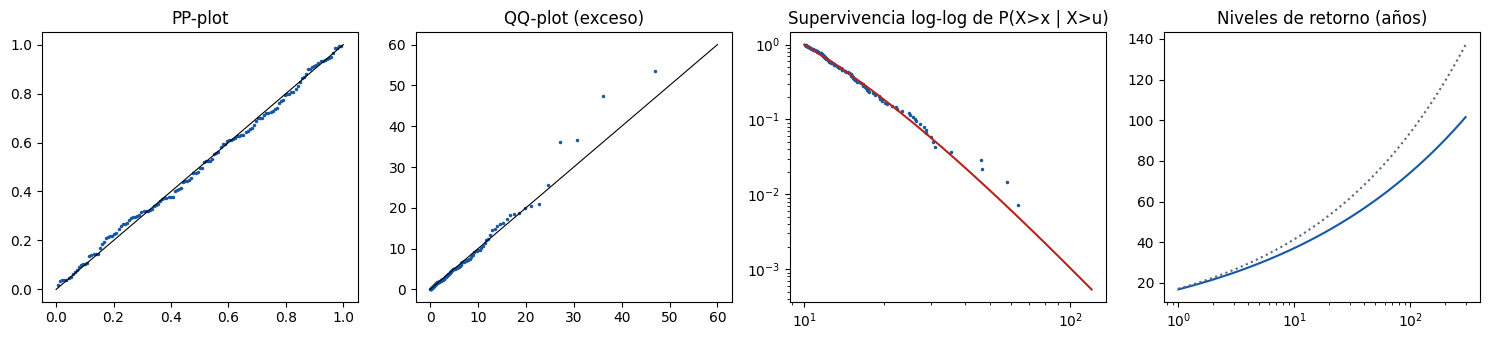

In [7]:
Gh = lambda yy: stats.genpareto.cdf(yy, xi_h, 0, sg_h)
pe = (np.arange(1, n_e + 1))/(n_e + 1)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
ax[0].plot(pe, Gh(y), ".", ms=3, color="#1559a6"); ax[0].plot([0, 1], [0, 1], "k", lw=.8); ax[0].set_title("PP-plot")
ax[1].plot(stats.genpareto.ppf(pe, xi_h, 0, sg_h), y, ".", ms=3, color="#1559a6"); mm = max(y.max(), 60); ax[1].plot([0, mm], [0, mm], "k", lw=.8); ax[1].set_title("QQ-plot (exceso)")
ax[2].loglog(y + u, 1 - pe, ".", ms=3, color="#1559a6"); xs_ = np.linspace(u, 120, 200); ax[2].loglog(xs_, stats.genpareto.sf(xs_ - u, xi_h, 0, sg_h), color="#b3261e"); ax[2].set_title("Supervivencia log-log de P(X>x | X>u)")
ms = np.logspace(0, np.log10(300), 60); ax[3].semilogx(ms, [nivel_retorno(m, u, xi_h, sg_h, Nu/T_AÑOS) for m in ms], color="#1559a6")
ax[3].semilogx(ms, [nivel_retorno(m, u, 1/3, 5.0*0 + sg_h, Nu/T_AÑOS) for m in ms], color="#57667a", ls=":"); ax[3].set_title("Niveles de retorno (años)")
plt.tight_layout(); plt.show()

**Lectura.** El PP y el QQ ajustan bien hasta ≈ 45 M€; la supervivencia log-log es casi una recta de pendiente ≈ −1/ξ. El máximo observado (63,6 M€) queda por encima de la banda: es una observación y no invalida el modelo, pero debe revisarse. Con 40 años de datos, el nivel a 200 años es 5 veces el historial.

## (E) De la severidad al SCR anual: simulación de la pérdida anual
Caso 1: $u=10$, $\xi=0{,}35$, $\sigma=6$, 10⁶ años simulados. $S$ = suma de las pérdidas por evento por encima de $u$ (en un año hay $N\sim$ Poisson($\lambda_u=2$)). Se comparan: Poisson, Binomial Negativa ($\mathrm{Var}=2{,}5\,\mathrm{media}$) y Poisson con incertidumbre de $\hat\xi,\hat\sigma$ ($N_u=80$).

In [8]:
def sim_anual(N, xi, sg, u0=10.0, rng=None):
    tot = N.sum(); anio = np.repeat(np.arange(len(N)), N); xs = u0 + stats.genpareto.rvs(xi if np.isscalar(xi) else np.repeat(xi, N), 0, sg if np.isscalar(sg) else np.repeat(sg, N), size=tot, random_state=rng)
    S = np.bincount(anio, weights=xs, minlength=len(N)); M = np.zeros(len(N)); np.maximum.at(M, anio, xs); return S, M
rng = np.random.default_rng(321); NY = 1_000_000
xi0, sg0, lam0 = .35, 6.0, 2.0
casos = {}
S, M = sim_anual(rng.poisson(lam0, NY), xi0, sg0, rng=rng); casos["Poisson (λ=2)"] = (S, M)
rr = lam0**2/(2.5*lam0 - lam0); S, M = sim_anual(rng.negative_binomial(rr, rr/(rr + lam0), NY), xi0, sg0, rng=rng); casos["Bin. Negativa (var = 2,5·media)"] = (S, M)
Nu_ = 80                                                      # covarianza asintótica de (ξ̂, σ̂): (1/Nu)·[[(1+ξ)², −σ(1+ξ)], [−σ(1+ξ), 2σ²(1+ξ)]]
cov_p = np.array([[(1 + xi0)**2, -sg0*(1 + xi0)], [-sg0*(1 + xi0), 2*sg0**2*(1 + xi0)]])/Nu_
par = rng.multivariate_normal([xi0, sg0], cov_p, NY); xi_s = np.clip(par[:, 0], -.3, .95); sg_s = np.clip(par[:, 1], 1, None)
S, M = sim_anual(rng.poisson(lam0, NY), xi_s, sg_s, rng=rng); casos["Poisson + incertidumbre de ξ, σ"] = (S, M)
tabE = pd.DataFrame({k: [S.mean(), np.quantile(S, .995), np.quantile(S, .995) - S.mean(), np.quantile(M, 1 - 1/200)] for k, (S, M) in casos.items()}, index=["E(S)", "VaR 99,5 % (S)", "SCR = VaR − E(S)", "OEP 1/200"]).T
print(f"VaR 99,5 % de severidad por evento = {var_gpd(.995, 10, .35, 6, 2000, 80):.2f} M€  ({100*var_gpd(.995, 10, .35, 6, 2000, 80)/tabE.iloc[0, 2]:.0f} % del SCR simulado)")
tabE.round(1)

VaR 99,5 % de severidad por evento = 28.35 M€  (19 % del SCR simulado)


,E(S),"VaR 99,5 % (S)",SCR = VaR − E(S),OEP 1/200
Poisson (λ=2),38.4,185.4,147.0,131.8
"Bin. Negativa (var = 2,5·media)",38.4,254.4,216.0,131.1
"Poisson + incertidumbre de ξ, σ",39.1,205.4,166.3,154.0


**Lectura.** El VaR 99,5 % de severidad (28,4 M€) es solo ≈ 19 % del SCR simulado (≈ 147 M€): *severidad ≠ capital*. El agrupamiento de eventos (BN) eleva el SCR ≈ 46 % sin cambiar la GPD; integrar la incertidumbre de parámetros con $N_u=80$ (cada año simulado con $(\hat\xi,\hat\sigma)$ distintos) añade ≈ 13 % al SCR y desplaza la OEP 1/200 de 132 a 154 M€ (la diapositiva informa +7 %; depende de cómo se propaga la incertidumbre).

## (F) Capa de reaseguro XL 40 xs 20
$E[(X-d)^+|X>u]=\frac{\sigma+\xi(d-u)}{1-\xi}\big[1+\xi(d-u)/\sigma\big]^{-1/\xi}$; $EL=\lambda_u\{E[(X-D)^+]-E[(X-D-L)^+]\}$; prima técnica $=EL+0{,}25\,\sigma_S$ con $\sigma_S^2=\lambda_u E[Y^2]$.

In [9]:
def esperado_exceso(d, u0, xi, sg): return (sg + xi*(d - u0))/(1 - xi)*(1 + xi*(d - u0)/sg)**(-1/xi)
def capa(D, L, u0, xi, sg, lam):
    sfy = lambda y: (1 + xi*(D + y - u0)/sg)**(-1/xi)
    EL = lam*(esperado_exceso(D, u0, xi, sg) - esperado_exceso(D + L, u0, xi, sg)); EY2 = integrate.quad(lambda y: 2*y*sfy(y), 0, L)[0]
    pc = 1 - np.exp(-lam*sfy(0)); pa = 1 - np.exp(-lam*sfy(L)); sdS = np.sqrt(lam*EY2); prima = EL + .25*sdS
    return [esperado_exceso(D, u0, xi, sg) - esperado_exceso(D + L, u0, xi, sg), EL, pc, pa, prima, prima/L]
capa_t = pd.DataFrame([[xi_] + capa(20, 40, 10, xi_, 6, 2) for xi_ in (.25, .35, .45)], columns=["ξ", "pérdida esperada por evento>u", "EL anual (prima pura)", "P(contacto) anual", "P(agotamiento) anual", "prima técnica", "rate on line"]).set_index("ξ")
capa_t["variación prima %"] = 100*(capa_t["prima técnica"]/capa_t.loc[.35, "prima técnica"] - 1)
print(f"Con recargo proporcional del 30 % sobre la prima pura (ξ=0,35): {1.3*capa_t.loc[.35, 'EL anual (prima pura)']:.2f} M€")
capa_t.round(3)

Con recargo proporcional del 30 % sobre la prima pura (ξ=0,35): 8.32 M€


,pérdida esperada por evento>u,EL anual (prima pura),P(contacto) anual,P(agotamiento) anual,prima técnica,rate on line,variación prima %
ξ,,,,,,,
0.25,2.541,5.082,0.391,0.022,7.671,0.192,-19.101
0.35,3.201,6.401,0.416,0.040,9.482,0.237,0.000
0.45,3.880,7.761,0.438,0.061,11.298,0.282,19.146


**Lectura.** Un error de ±0,10 en $\hat\xi$ mueve la prima técnica ≈ ±19 %: la incertidumbre de cola se traslada al precio. La prima pura exige $\lambda_u$, no solo la GPD.

## (G) Datos con límites de póliza (censura) y no estacionariedad
**Censura.** Los siniestros topados en $c=30$ M€ aportan $\ln S(c)$ y no $\ln f(c)$. Ignorarlo sesga $\hat\xi$ a la baja.

In [10]:
c_lim = 30.0; capped = np.minimum(claims, c_lim); e_c = capped[capped > u] - u; cens = (capped[capped > u] >= c_lim)
f_naive, _ = mle_gpd(e_c)
def nll_cens(p):
    if p[1] <= 0: return np.inf
    return -(np.sum(stats.genpareto.logpdf(e_c[~cens], p[0], 0, p[1])) + np.sum(stats.genpareto.logsf(e_c[cens], p[0], 0, p[1])))
rc = optimize.minimize(nll_cens, [.2, 4], method="Nelder-Mead", options=dict(xatol=1e-9, fatol=1e-10, maxiter=4000)); f_cens = rc.x
print(f"Sin límite (datos completos): ξ = {xi_h:.3f}  σ = {sg_h:.3f}  VaR = {var_de(xi_h, sg_h):.2f}")
print(f"Con límite en {c_lim:.0f} M€ ({cens.sum()} siniestros topados): ingenuo ξ = {f_naive[0]:.3f} σ = {f_naive[1]:.3f} VaR = {var_gpd(.995, u, f_naive[0], f_naive[1], N_TOT, len(e_c)):.2f} | censurado ξ = {f_cens[0]:.3f} σ = {f_cens[1]:.3f} VaR = {var_gpd(.995, u, f_cens[0], f_cens[1], N_TOT, len(e_c)):.2f}")

Sin límite (datos completos): ξ = 0.262  σ = 4.665  VaR = 27.53
Con límite en 30 M€ (7 siniestros topados): ingenuo ξ = 0.019 σ = 5.447 VaR = 24.63 | censurado ξ = 0.236 σ = 4.728 VaR = 27.11


In [11]:
import statsmodels.api as sm
rng = np.random.default_rng(99); años = np.arange(1985, 2025); lam_t = 2*np.exp(.022*(años - 2004.5)*1.0)
cnt = rng.poisson(lam_t); X1 = sm.add_constant(años - 2004.5)
m1 = sm.GLM(cnt, X1, family=sm.families.Poisson()).fit(); m0 = sm.GLM(cnt, np.ones((len(cnt), 1)), family=sm.families.Poisson()).fit()
LR = 2*(m1.llf - m0.llf); lam_est = np.exp(m1.params[0] + m1.params[1]*(2025 - 2004.5)); lam_stat = cnt.mean()
xi2, sg2, u2 = .25, 4.0, 5.0
print(f"β1 = {m1.params[1]:.4f} (EE {m1.bse[1]:.4f})   LR = {LR:.2f}  p = {stats.chi2.sf(LR, 1):.3f}   frecuencia +{100*(np.exp(10*m1.params[1]) - 1):.0f} % por década")
print(f"λ_u 2025: con tendencia = {lam_est:.2f} | estacionario = {lam_stat:.2f} ({100*(lam_stat/lam_est - 1):.0f} %)")
print(f"Nivel de retorno 100 años: estacionario {nivel_retorno(100, u2, xi2, sg2, lam_stat):.1f} | con tendencia {nivel_retorno(100, u2, xi2, sg2, lam_est):.1f}   200 años: {nivel_retorno(200, u2, xi2, sg2, lam_stat):.1f} | {nivel_retorno(200, u2, xi2, sg2, lam_est):.1f}")

β1 = 0.0253 (EE 0.0094)   LR = 7.47  p = 0.006   frecuencia +29 % por década
λ_u 2025: con tendencia = 3.62 | estacionario = 2.25 (-38 %)
Nivel de retorno 100 años: estacionario 51.0 | con tendencia 58.8   200 años: 62.7 | 72.0


**Lectura.** (Simulación propia con semilla 99; no reproduce las cifras exactas de la diapositiva, cuyo conjunto de datos no se facilita.) Un límite de póliza ignorado sesga ξ̂ a la baja y el VaR con él; la verosimilitud censurada lo corrige.
Con una tendencia del ≈ 25 % por década en la frecuencia, suponer estacionariedad infravalora el λ actual y los niveles de retorno.